In [11]:
import pandapower as pp
import pandas as pd
import matplotlib.pyplot as plt
from pandapower.networks.power_system_test_cases import case14


net = case14() # Load the IEEE 14-bus test case
pp.runpp(net)  # Run power flow analysis

In [12]:
# initial value as a pq bus
bus_types = pd.Series("PQ", index=net.bus.index, name="type")

# if it has a generator in service, it's actually pv
generators = net.gen[net.gen.in_service]
bus_types.loc[generators.bus] = "PV"

# if its connected an external grid, its a slack bus
external_grid_buses = net.ext_grid[net.ext_grid.in_service].bus
bus_types.loc[external_grid_buses] = "Slack"

# print table
table = pd.concat([bus_types, net.res_bus], axis=1)
table.index.name = "Bus"
print(table)
print(bus_types.value_counts())
print(table.round(3).to_markdown())

      type     vm_pu  va_degree        p_mw     q_mvar
Bus                                                   
0    Slack  1.060000   0.000000 -232.393272  16.549301
1       PV  1.045000  -4.982589  -18.300000 -30.857100
2       PV  1.010000 -12.725100   94.200000  -6.075348
3       PQ  1.017671 -10.312901   47.800000  -3.900000
4       PQ  1.019514  -8.773854    7.600000   1.600000
5       PV  1.070000 -14.220946   11.200000  -5.230944
6       PQ  1.061520 -13.359627    0.000000   0.000000
7       PV  1.090000 -13.359627    0.000000 -17.623451
8       PQ  1.055932 -14.938521   29.500000  -4.584844
9       PQ  1.050985 -15.097288    9.000000   5.800000
10      PQ  1.056907 -14.790622    3.500000   1.800000
11      PQ  1.055189 -15.075585    6.100000   1.600000
12      PQ  1.050382 -15.156276   13.500000   5.800000
13      PQ  1.035530 -16.033645   14.900000   5.000000
type
PQ       9
PV       4
Slack    1
Name: count, dtype: int64
|   Bus | type   |   vm_pu |   va_degree |     p_mw |   

In [13]:
# print result tables of bus and lines in markdown format
print(net.res_bus[["vm_pu", "va_degree"]].round(3).to_markdown())
print("\n")
print(net.res_line[["loading_percent"]].round(3).to_markdown())

|    |   vm_pu |   va_degree |
|---:|--------:|------------:|
|  0 |   1.06  |       0     |
|  1 |   1.045 |      -4.983 |
|  2 |   1.01  |     -12.725 |
|  3 |   1.018 |     -10.313 |
|  4 |   1.02  |      -8.774 |
|  5 |   1.07  |     -14.221 |
|  6 |   1.062 |     -13.36  |
|  7 |   1.09  |     -13.36  |
|  8 |   1.056 |     -14.939 |
|  9 |   1.051 |     -15.097 |
| 10 |   1.057 |     -14.791 |
| 11 |   1.055 |     -15.076 |
| 12 |   1.05  |     -15.156 |
| 13 |   1.036 |     -16.034 |


|    |   loading_percent |
|---:|------------------:|
|  0 |             1.508 |
|  1 |             0.721 |
|  2 |             0.709 |
|  3 |             0.543 |
|  4 |             0.403 |
|  5 |             0.24  |
|  6 |             0.627 |
|  7 |             0.077 |
|  8 |             0.077 |
|  9 |             0.181 |
| 10 |             0.064 |
| 11 |             0.097 |
| 12 |             0.04  |
| 13 |             0.017 |
| 14 |             0.057 |


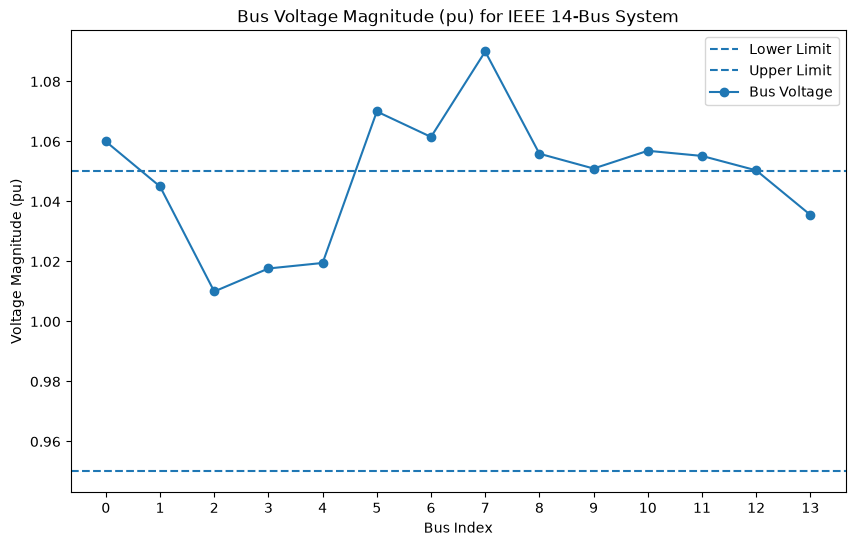

In [25]:
# plot vm_pu (voltage magnitude)
buses = net.bus.index
vm_pu = net.res_bus["vm_pu"]
figure = plt.figure(figsize=(10, 6))
plt.axhline(y=0.95, label="Lower Limit", linestyle="--")
plt.axhline(y=1.05, label="Upper Limit", linestyle="--")
plt.plot(buses, vm_pu, marker="o", linestyle="-", label="Bus Voltage")
plt.xticks(buses)
plt.xlabel("Bus Index")
plt.ylabel("Voltage Magnitude (pu)")
plt.title("Bus Voltage Magnitude (pu) for IEEE 14-Bus System")
plt.legend()
plt.show()